# General Comment

### This is the first notebook of the project, its mainly about EDA and exploring the dataset before diving into the model training

# Imports

In [1]:
# Import the libraries used throughout the EDA notebook.

import os
import random
import xml.etree.ElementTree as ET
from collections import Counter, defaultdict

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch


# Seeding

In [2]:
# Set a fixed random seed for reproducible results across Python, NumPy, and PyTorch.

# ==========================================================
# Reproducibility / Global Seed
# ==========================================================

SEED = 42

# Python
random.seed(SEED)

# Numpy
np.random.seed(SEED)

# Hash seed
os.environ["PYTHONHASHSEED"] = str(SEED)

# PyTorch
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# CuDNN
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print(f"Seed set to {SEED}")

Seed set to 42


# EDA

In [3]:
# Define the dataset location and defect classes, then preview the dataset folder structure.

dataset_path = "/kaggle/input/datasets/alimaged10/pcb-dataset/PCB-DATASET-master"

classes = [
    "Missing_hole",
    "Mouse_bite",
    "Open_circuit",
    "Short",
    "Spur",
    "Spurious_copper"
]


for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, '').count(os.sep)
    indent = ' ' * 4 * level
    print(f"{indent}{os.path.basename(root)}/")
    
    if level < 2:  # prevent huge output
        subindent = ' ' * 4 * (level + 1)
        for f in files[:10]:
            print(f"{subindent}{f}")

PCB-DATASET-master/
    rotate.py
    README.md
    PCB_USED/
        10.JPG
        01.JPG
        09.JPG
        05.JPG
        06.JPG
        04.JPG
        12.JPG
        11.JPG
        08.JPG
        07.JPG
    Annotations/
        Mouse_bite/
        Spur/
        Open_circuit/
        Short/
        Missing_hole/
        Spurious_copper/
    images/
        Mouse_bite/
        Spur/
        Open_circuit/
        Short/
        Missing_hole/
        Spurious_copper/
    rotation/
        Mouse_bite_angles.txt
        Missing_hole_angles.txt
        Spurious_copper_angles.txt
        Spur_angles.txt
        Short_angles.txt
        Open_circuit_angles.txt
        Missing_hole_rotation/
        Spur_rotation/
        Open_circuit_rotation/
        Short_rotation/
        Spurious_copper_rotation/
        Mouse_bite_rotation/


In [4]:
# Count the number of image files available for each defect class.

print("IMAGE COUNTS")
print("-" * 40)

total_images = 0

for cls in classes:
    img_dir = os.path.join(dataset_path, "images", cls)

    images = [
        f for f in os.listdir(img_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    count = len(images)
    total_images += count

    print(f"{cls:<20} {count}")

print("-" * 40)
print(f"TOTAL IMAGES: {total_images}")

IMAGE COUNTS
----------------------------------------
Missing_hole         115
Mouse_bite           115
Open_circuit         116
Short                116
Spur                 115
Spurious_copper      116
----------------------------------------
TOTAL IMAGES: 693


In [5]:
# Count the total annotated defects in the XML files for each class.

print("DEFECT COUNTS")
print("-" * 40)

total_defects = 0

for cls in classes:

    xml_dir = os.path.join(
        dataset_path,
        "Annotations",
        cls
    )

    defect_count = 0

    for xml_file in os.listdir(xml_dir):

        if not xml_file.endswith(".xml"):
            continue

        tree = ET.parse(os.path.join(xml_dir, xml_file))
        root = tree.getroot()

        objects = root.findall("object")

        defect_count += len(objects)

    total_defects += defect_count

    print(f"{cls:<20} {defect_count}")

print("-" * 40)
print(f"TOTAL DEFECTS: {total_defects}")

DEFECT COUNTS
----------------------------------------
Missing_hole         497
Mouse_bite           492
Open_circuit         482
Short                491
Spur                 488
Spurious_copper      503
----------------------------------------
TOTAL DEFECTS: 2953


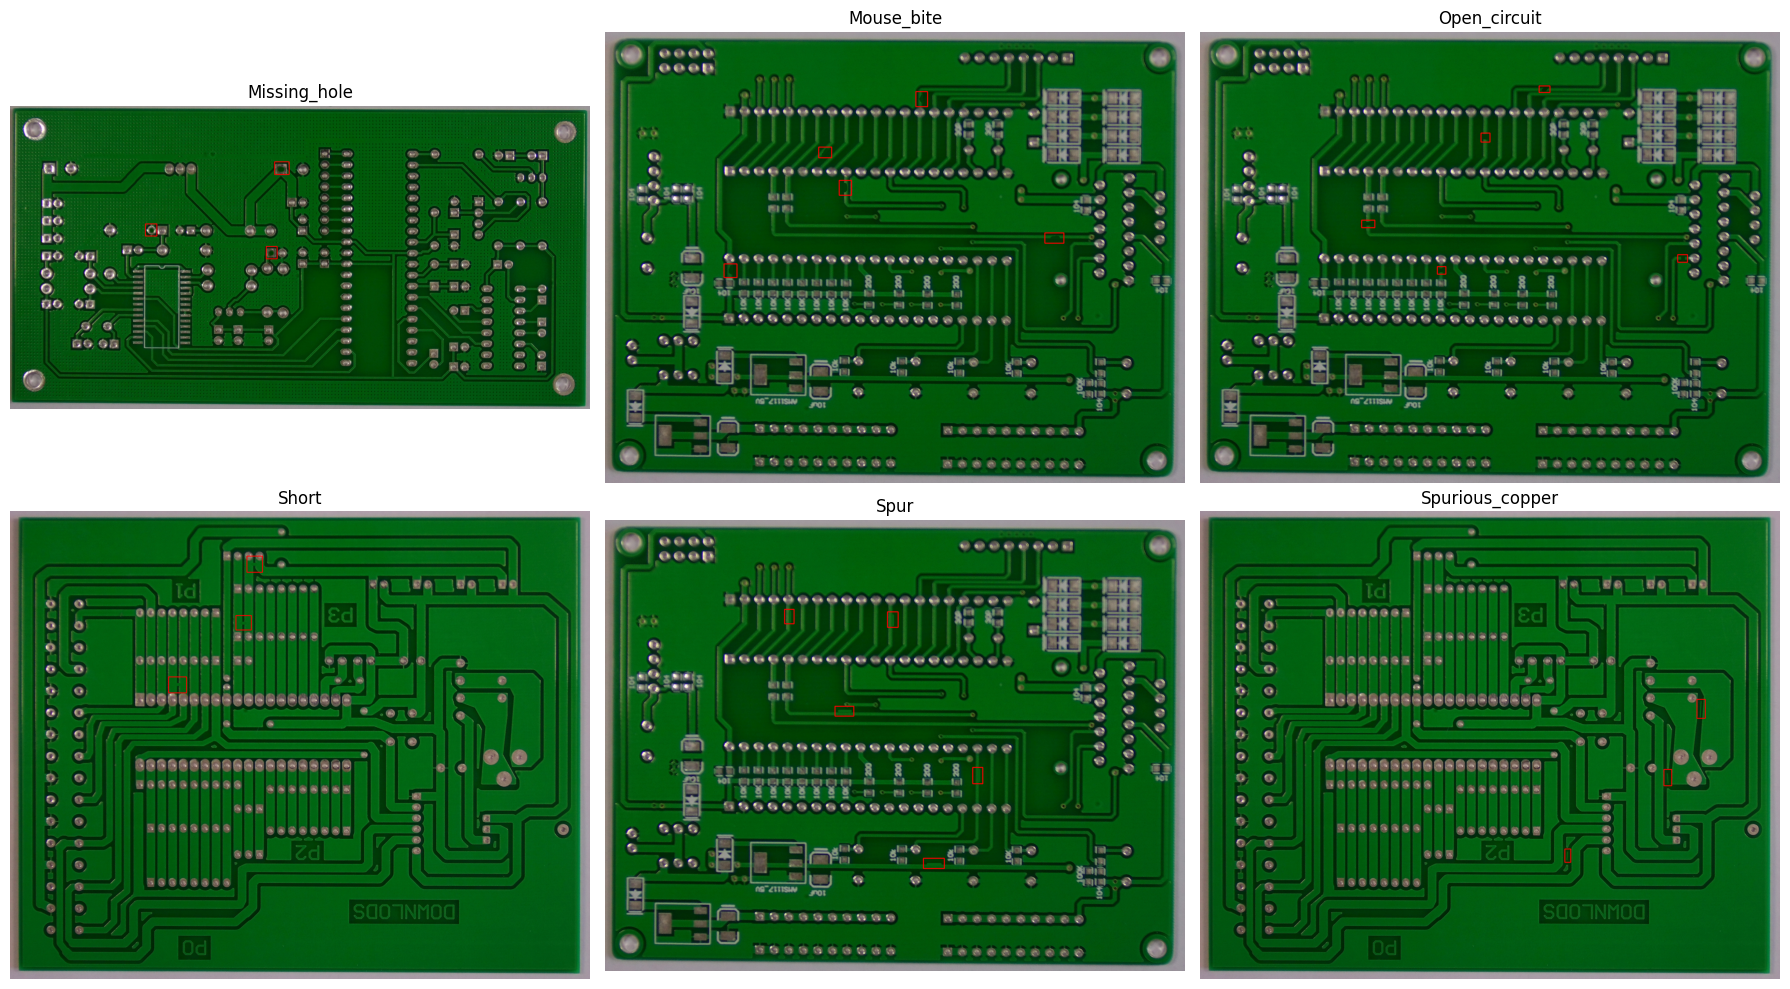

In [6]:
# Display one random image per class with its annotated bounding boxes.

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, cls in zip(axes.ravel(), classes):

    img_dir = os.path.join(dataset_path, "images", cls)
    ann_dir = os.path.join(dataset_path, "Annotations", cls)

    img_name = random.choice(
        [f for f in os.listdir(img_dir) if f.endswith(".jpg")]
    )

    img_path = os.path.join(img_dir, img_name)

    xml_path = os.path.join(
        ann_dir,
        img_name.replace(".jpg", ".xml")
    )

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    tree = ET.parse(xml_path)
    root = tree.getroot()

    for obj in root.findall("object"):

        bbox = obj.find("bndbox")

        xmin = int(bbox.find("xmin").text)
        ymin = int(bbox.find("ymin").text)
        xmax = int(bbox.find("xmax").text)
        ymax = int(bbox.find("ymax").text)

        cv2.rectangle(
            img,
            (xmin, ymin),
            (xmax, ymax),
            (255, 0, 0),
            3
        )

    ax.imshow(img)
    ax.set_title(cls)
    ax.axis("off")

plt.tight_layout()
plt.show()

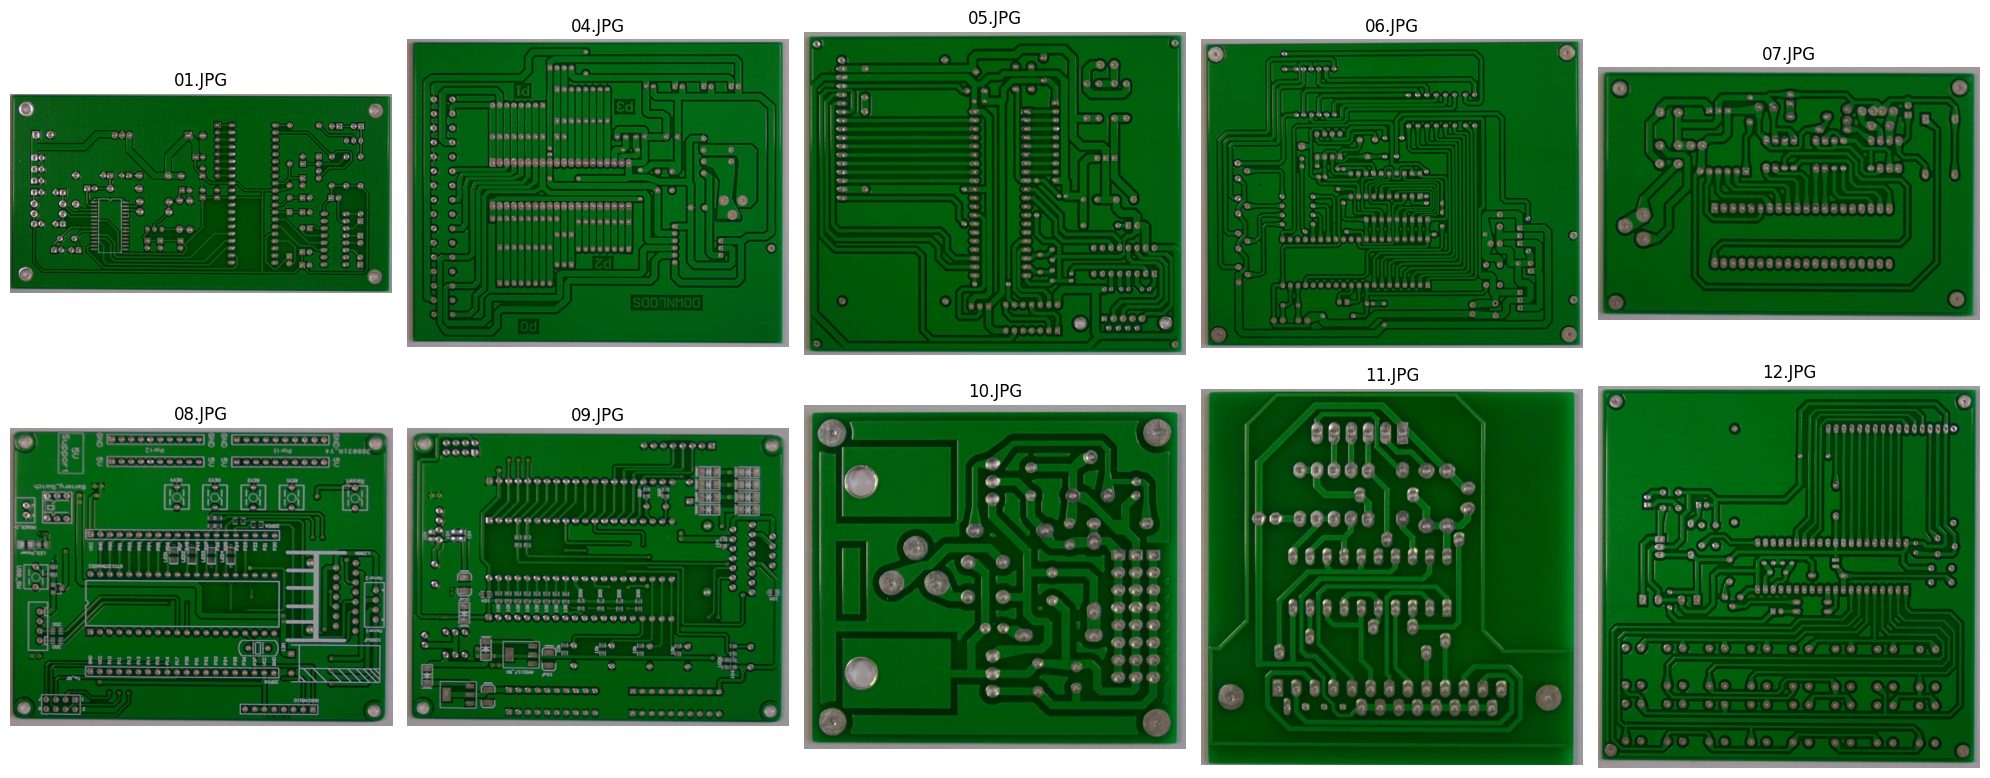

In [7]:
# Display the PCB template images used to generate the defect dataset.

template_dir = os.path.join(dataset_path, "PCB_USED")

template_files = sorted(os.listdir(template_dir))

fig, axes = plt.subplots(2, 5, figsize=(20, 8))

for ax, file in zip(axes.ravel(), template_files):

    img_path = os.path.join(template_dir, file)

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    ax.imshow(img)
    ax.set_title(file)
    ax.axis("off")

plt.tight_layout()
plt.show()

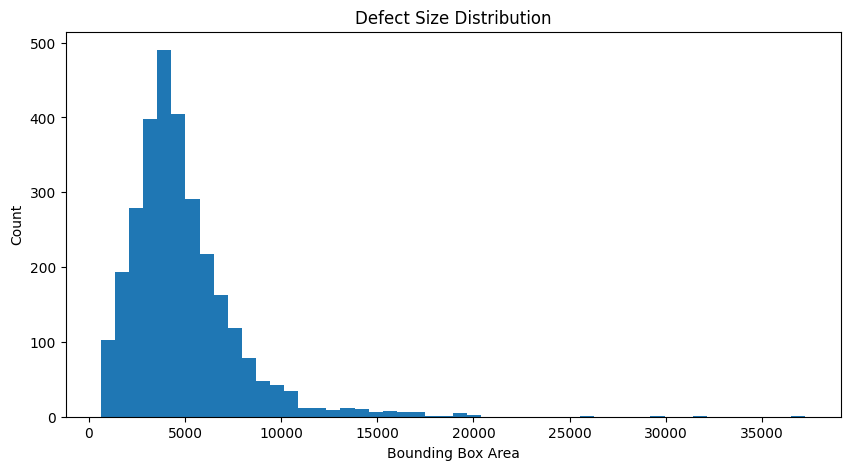

Min Area : 625
Max Area : 37268
Mean Area: 4860.04537758212
Median Area: 4312.0


In [8]:
# Compute and plot the distribution of bounding-box areas across all defects.

areas = []

for cls in classes:

    xml_dir = os.path.join(
        dataset_path,
        "Annotations",
        cls
    )

    for xml_file in os.listdir(xml_dir):

        if not xml_file.endswith(".xml"):
            continue

        tree = ET.parse(
            os.path.join(xml_dir, xml_file)
        )

        root = tree.getroot()

        for obj in root.findall("object"):

            bbox = obj.find("bndbox")

            xmin = int(bbox.find("xmin").text)
            ymin = int(bbox.find("ymin").text)
            xmax = int(bbox.find("xmax").text)
            ymax = int(bbox.find("ymax").text)

            w = xmax - xmin
            h = ymax - ymin

            areas.append(w * h)

plt.figure(figsize=(10,5))

plt.hist(
    areas,
    bins=50
)

plt.xlabel("Bounding Box Area")
plt.ylabel("Count")
plt.title("Defect Size Distribution")

plt.show()

print("Min Area :", min(areas))
print("Max Area :", max(areas))
print("Mean Area:", np.mean(areas))
print("Median Area:", np.median(areas))

<Figure size 1000x600 with 0 Axes>

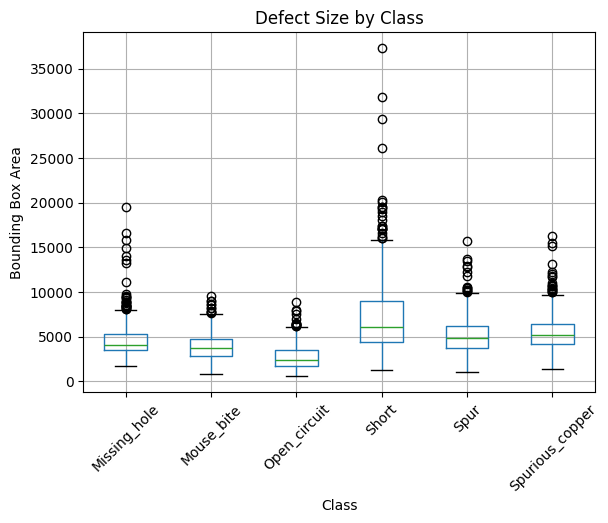

                        mean     50%     min      max
Class                                                
Missing_hole     4700.321932  4092.0  1681.0  19460.0
Mouse_bite       3884.213415  3723.5   800.0   9516.0
Open_circuit     2715.259336  2434.0   625.0   8924.0
Short            7230.417515  6084.0  1254.0  37268.0
Spur             5121.247951  4893.0   990.0  15708.0
Spurious_copper  5460.361829  5198.0  1400.0  16241.0


In [9]:
# Compare bounding-box area statistics across defect classes.

data = []

for cls in classes:

    xml_dir = os.path.join(
        dataset_path,
        "Annotations",
        cls
    )

    for xml_file in os.listdir(xml_dir):

        if not xml_file.endswith(".xml"):
            continue

        tree = ET.parse(
            os.path.join(xml_dir, xml_file)
        )

        root = tree.getroot()

        for obj in root.findall("object"):

            bbox = obj.find("bndbox")

            xmin = int(bbox.find("xmin").text)
            ymin = int(bbox.find("ymin").text)
            xmax = int(bbox.find("xmax").text)
            ymax = int(bbox.find("ymax").text)

            area = (xmax - xmin) * (ymax - ymin)

            data.append([cls, area])

df = pd.DataFrame(
    data,
    columns=["Class", "Area"]
)

plt.figure(figsize=(10,6))

df.boxplot(
    column="Area",
    by="Class",
    rot=45
)

plt.ylabel("Bounding Box Area")
plt.title("Defect Size by Class")
plt.suptitle("")

plt.show()

print(
    df.groupby("Class")["Area"]
      .describe()[["mean","50%","min","max"]]
)

In [10]:
# Count annotated defects per PCB template ID.

template_counter = Counter()

for cls in classes:

    ann_dir = os.path.join(
        dataset_path,
        "Annotations",
        cls
    )

    for xml_file in os.listdir(ann_dir):

        if not xml_file.endswith(".xml"):
            continue

        template_id = xml_file[:2]

        tree = ET.parse(
            os.path.join(ann_dir, xml_file)
        )

        root = tree.getroot()

        num_defects = len(root.findall("object"))

        template_counter[template_id] += num_defects

print("Template Defect Counts")
print("-" * 40)

for k, v in sorted(template_counter.items()):
    print(f"{k}: {v}")

Template Defect Counts
----------------------------------------
01: 358
04: 358
05: 259
06: 307
07: 300
08: 298
09: 305
10: 162
11: 303
12: 303


count    2953.000000
mean        1.152916
std         0.599811
min         0.169492
25%         0.819444
50%         1.026316
75%         1.325843
max        10.481481
Name: AspectRatio, dtype: float64


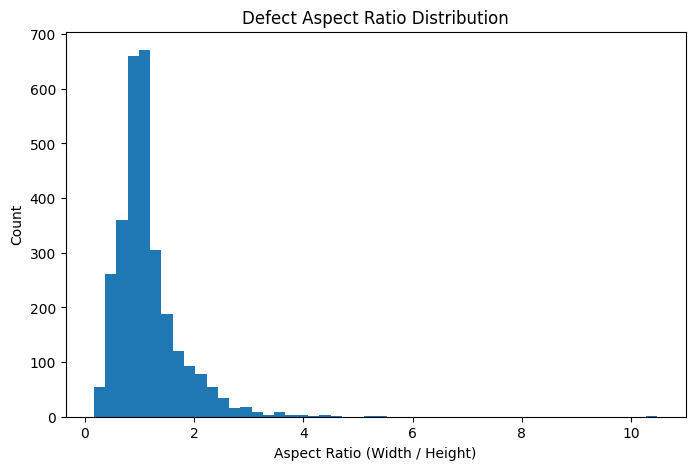

In [11]:
# Analyze the aspect-ratio distribution of defect bounding boxes.

data = []

for cls in classes:

    xml_dir = os.path.join(
        dataset_path,
        "Annotations",
        cls
    )

    for xml_file in os.listdir(xml_dir):

        if not xml_file.endswith(".xml"):
            continue

        tree = ET.parse(
            os.path.join(xml_dir, xml_file)
        )

        root = tree.getroot()

        for obj in root.findall("object"):

            bbox = obj.find("bndbox")

            xmin = int(bbox.find("xmin").text)
            ymin = int(bbox.find("ymin").text)
            xmax = int(bbox.find("xmax").text)
            ymax = int(bbox.find("ymax").text)

            w = xmax - xmin
            h = ymax - ymin

            aspect_ratio = w / h

            data.append([cls, w, h, aspect_ratio])

df = pd.DataFrame(
    data,
    columns=["Class", "Width", "Height", "AspectRatio"]
)

print(df["AspectRatio"].describe())

plt.figure(figsize=(8,5))
plt.hist(df["AspectRatio"], bins=50)
plt.xlabel("Aspect Ratio (Width / Height)")
plt.ylabel("Count")
plt.title("Defect Aspect Ratio Distribution")
plt.show()

In [12]:
# Inspect image dimensions and channel counts for the original dataset images.

records = []

for cls in classes:

    img_dir = os.path.join(dataset_path, "images", cls)

    for img_name in os.listdir(img_dir):

        if not img_name.lower().endswith(".jpg"):
            continue

        img_path = os.path.join(img_dir, img_name)

        img = cv2.imread(img_path)

        h, w, c = img.shape

        records.append([cls, img_name, w, h, c])

df = pd.DataFrame(
    records,
    columns=["Class","Image","Width","Height","Channels"]
)

print(df[["Width","Height","Channels"]].describe())

print("\nUnique Widths:", df["Width"].nunique())
print("Unique Heights:", df["Height"].nunique())
print("Unique Channel Counts:", df["Channels"].unique())

             Width       Height  Channels
count   693.000000   693.000000     693.0
mean   2777.789322  2138.337662       3.0
std     267.820947   305.439542       0.0
min    2240.000000  1586.000000       3.0
25%    2544.000000  1921.000000       3.0
50%    2868.000000  2159.000000       3.0
75%    3034.000000  2464.000000       3.0
max    3056.000000  2530.000000       3.0

Unique Widths: 10
Unique Heights: 10
Unique Channel Counts: [3]


In [13]:
# Compute the dataset-level RGB mean and standard deviation for normalization.

means = []
stds = []

for cls in classes:

    img_dir = os.path.join(dataset_path, "images", cls)

    for img_name in os.listdir(img_dir):

        if not img_name.lower().endswith(".jpg"):
            continue

        img = cv2.imread(
            os.path.join(img_dir, img_name)
        )

        img = cv2.cvtColor(
            img,
            cv2.COLOR_BGR2RGB
        )

        img = img / 255.0

        means.append(
            img.mean(axis=(0,1))
        )

        stds.append(
            img.std(axis=(0,1))
        )

means = np.array(means)
stds = np.array(stds)

dataset_mean = means.mean(axis=0)
dataset_std = stds.mean(axis=0)

print("Dataset Mean RGB:")
print(dataset_mean)

print("\nDataset Std RGB:")
print(dataset_std)

Dataset Mean RGB:
[0.0833437  0.33700574 0.11266432]

Dataset Std RGB:
[0.1721115  0.10782468 0.14567144]


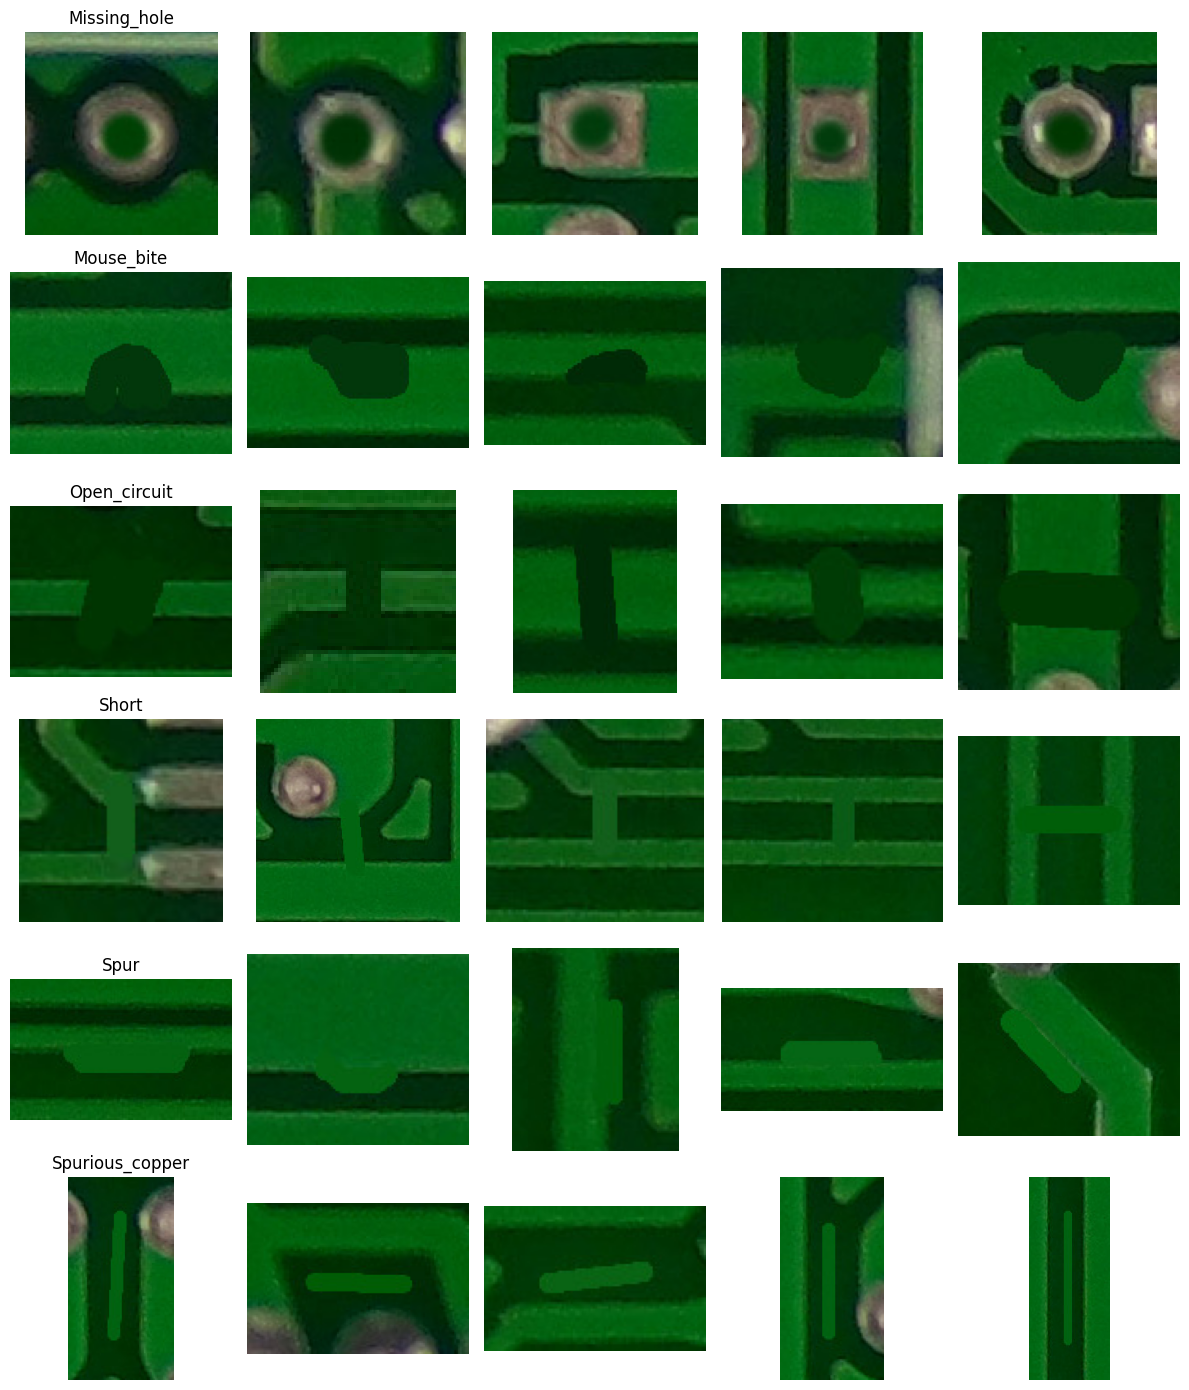

In [14]:
# Show random cropped examples of annotated defects for each class.

fig, axes = plt.subplots(
    len(classes),
    5,
    figsize=(12, 14)
)

for row, cls in enumerate(classes):

    img_dir = os.path.join(dataset_path, "images", cls)
    ann_dir = os.path.join(dataset_path, "Annotations", cls)

    shown = 0

    while shown < 5:

        img_name = random.choice(
            [f for f in os.listdir(img_dir)
             if f.endswith(".jpg")]
        )

        img_path = os.path.join(img_dir, img_name)

        xml_path = os.path.join(
            ann_dir,
            img_name.replace(".jpg", ".xml")
        )

        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        tree = ET.parse(xml_path)
        root = tree.getroot()

        objects = root.findall("object")

        if len(objects) == 0:
            continue

        obj = random.choice(objects)

        bbox = obj.find("bndbox")

        xmin = int(bbox.find("xmin").text)
        ymin = int(bbox.find("ymin").text)
        xmax = int(bbox.find("xmax").text)
        ymax = int(bbox.find("ymax").text)

        pad = 15

        crop = img[
            max(0, ymin-pad):ymax+pad,
            max(0, xmin-pad):xmax+pad
        ]

        axes[row, shown].imshow(crop)
        axes[row, shown].axis("off")

        if shown == 0:
            axes[row, shown].set_title(cls)

        shown += 1

plt.tight_layout()
plt.show()

In [15]:
# Summarize template image sizes and how often each template appears in the original images.

# Count original images per template
template_freq = Counter()

for cls in classes:

    img_dir = os.path.join(dataset_path, "images", cls)

    for img_name in os.listdir(img_dir):

        if img_name.lower().endswith(".jpg"):

            template_id = img_name[:2]
            template_freq[template_id] += 1

records = []

template_dir = os.path.join(dataset_path, "PCB_USED")

for file in sorted(os.listdir(template_dir)):

    if not file.lower().endswith(".jpg"):
        continue

    img = cv2.imread(
        os.path.join(template_dir, file)
    )

    h, w = img.shape[:2]

    template_id = file[:2]

    records.append([
        template_id,
        file,
        w,
        h,
        template_freq[template_id]
    ])

df_templates = pd.DataFrame(
    records,
    columns=[
        "Template_ID",
        "Template_File",
        "Width",
        "Height",
        "Original_Image_Count"
    ]
)

df_templates = df_templates.sort_values(
    "Template_ID"
).reset_index(drop=True)

print(df_templates)

  Template_ID Template_File  Width  Height  Original_Image_Count
0          01        01.JPG   3034    1586                   120
1          04        04.JPG   3056    2464                   120
2          05        05.JPG   2544    2156                    60
3          06        06.JPG   2868    2316                    61
4          07        07.JPG   2904    1921                    60
5          08        08.JPG   2759    2154                    60
6          09        09.JPG   2775    2159                    60
7          10        10.JPG   2240    2016                    32
8          11        11.JPG   2282    2248                    60
9          12        12.JPG   2529    2530                    60


In [16]:
# Count original image dimensions grouped by template ID.

records = defaultdict(int)

for cls in classes:

    img_dir = os.path.join(
        dataset_path,
        "images",
        cls
    )

    for img_name in os.listdir(img_dir):

        if not img_name.lower().endswith(".jpg"):
            continue

        template_id = img_name[:2]

        img = cv2.imread(
            os.path.join(img_dir, img_name)
        )

        h, w = img.shape[:2]

        records[(template_id, w, h)] += 1

rows = []

for (template_id, w, h), freq in records.items():

    rows.append([
        template_id,
        w,
        h,
        freq
    ])

df_original = pd.DataFrame(
    rows,
    columns=[
        "Template_ID",
        "Width",
        "Height",
        "Frequency"
    ]
)

df_original = df_original.sort_values(
    "Template_ID"
).reset_index(drop=True)

print(df_original)

  Template_ID  Width  Height  Frequency
0          01   3034    1586        120
1          04   3056    2464        120
2          05   2544    2156         60
3          06   2868    2316         61
4          07   2904    1921         60
5          08   2759    2154         60
6          09   2775    2159         60
7          10   2240    2016         32
8          11   2282    2248         60
9          12   2529    2530         60


In [17]:
# Count rotated image dimensions grouped by template ID.

rotation_root = os.path.join(
    dataset_path,
    "rotation"
)

records = defaultdict(int)

for folder in os.listdir(rotation_root):

    folder_path = os.path.join(
        rotation_root,
        folder
    )

    if not os.path.isdir(folder_path):
        continue

    for img_name in os.listdir(folder_path):

        if not img_name.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):
            continue

        template_id = img_name[:2]

        img = cv2.imread(
            os.path.join(folder_path, img_name)
        )

        if img is None:
            continue

        h, w = img.shape[:2]

        records[(template_id, w, h)] += 1

rows = []

for (template_id, w, h), freq in records.items():

    rows.append([
        template_id,
        w,
        h,
        freq
    ])

df_rotated = pd.DataFrame(
    rows,
    columns=[
        "Template_ID",
        "Width",
        "Height",
        "Frequency"
    ]
)

df_rotated = df_rotated.sort_values(
    "Template_ID"
).reset_index(drop=True)

print(df_rotated)

print("\nTotal Rotated Images:",
      df_rotated["Frequency"].sum())

    Template_ID  Width  Height  Frequency
0            01   3137    1793         14
1            01   3244    2041         14
2            01   3225    1992          7
3            01   3204    1943         13
4            01   3061    1638         13
..          ...    ...     ...        ...
104          12   2572    2573          8
105          12   2818    2819          9
106          12   2893    2894          8
107          12   2699    2700          7
108          12   2615    2616          8

[109 rows x 4 columns]

Total Rotated Images: 693


In [18]:
# Build a template-by-class table of annotation counts.

templates = sorted([
    "01","04","05","06","07",
    "08","09","10","11","12"
])

results = []

for template_id in templates:

    row = {"Template": template_id}
    total = 0

    for cls in classes:

        xml_dir = os.path.join(
            dataset_path,
            "Annotations",
            cls
        )

        count = 0

        for xml_file in os.listdir(xml_dir):

            if not xml_file.endswith(".xml"):
                continue

            if not xml_file.startswith(template_id):
                continue

            tree = ET.parse(
                os.path.join(xml_dir, xml_file)
            )

            root = tree.getroot()

            count += len(root.findall("object"))

        row[cls] = count
        total += count

    row["Total"] = total

    results.append(row)

df_template_class = pd.DataFrame(results)

print(df_template_class)

  Template  Missing_hole  Mouse_bite  Open_circuit  Short  Spur  \
0       01            61          53            59     72    53   
1       04            60          60            59     59    60   
2       05            46          51            32     30    50   
3       06            51          52            50     55    49   
4       07            50          50            50     50    50   
5       08            49          50            50     49    50   
6       09            53          50            51     50    50   
7       10            25          26            30     25    25   
8       11            50          50            51     51    50   
9       12            52          50            50     50    51   

   Spurious_copper  Total  
0               60    358  
1               60    358  
2               50    259  
3               50    307  
4               50    300  
5               50    298  
6               51    305  
7               31    162  
8         

In [19]:
# Calculate average bounding-box width, height, and area for each defect class.

records = []

for cls in classes:

    xml_dir = os.path.join(
        dataset_path,
        "Annotations",
        cls
    )

    for xml_file in os.listdir(xml_dir):

        if not xml_file.endswith(".xml"):
            continue

        tree = ET.parse(
            os.path.join(xml_dir, xml_file)
        )

        root = tree.getroot()

        for obj in root.findall("object"):

            bbox = obj.find("bndbox")

            xmin = int(bbox.find("xmin").text)
            ymin = int(bbox.find("ymin").text)
            xmax = int(bbox.find("xmax").text)
            ymax = int(bbox.find("ymax").text)

            w = xmax - xmin
            h = ymax - ymin

            records.append([
                cls,
                w,
                h,
                w * h
            ])

df_dims = pd.DataFrame(
    records,
    columns=[
        "Class",
        "Width",
        "Height",
        "Area"
    ]
)

summary = (
    df_dims
    .groupby("Class")
    .agg({
        "Width":"mean",
        "Height":"mean",
        "Area":"mean"
    })
    .round(2)
)

print(summary)

                 Width  Height     Area
Class                                  
Missing_hole     66.76   68.10  4700.32
Mouse_bite       63.07   61.43  3884.21
Open_circuit     52.36   49.79  2715.26
Short            86.74   78.75  7230.42
Spur             75.41   69.36  5121.25
Spurious_copper  80.21   77.48  5460.36


In [20]:
# Print overall mean and median bounding-box dimensions from the prepared summary data.

print("Average Width :", round(df_dims["Width"].mean(),2))
print("Average Height:", round(df_dims["Height"].mean(),2))
print("Average Area  :", round(df_dims["Area"].mean(),2))

print("\nMedian Width :", round(df_dims["Width"].median(),2))
print("Median Height:", round(df_dims["Height"].median(),2))
print("Median Area  :", round(df_dims["Area"].median(),2))

Average Width : 70.84
Average Height: 67.58
Average Area  : 4860.05

Median Width : 64.0
Median Height: 63.0
Median Area  : 4312.0


In [21]:
# List the frequency of each unique bounding-box size within every class.

for cls in classes:

    counter = Counter()

    xml_dir = os.path.join(
        dataset_path,
        "Annotations",
        cls
    )

    for xml_file in os.listdir(xml_dir):

        if not xml_file.endswith(".xml"):
            continue

        tree = ET.parse(
            os.path.join(xml_dir, xml_file)
        )

        root = tree.getroot()

        for obj in root.findall("object"):

            bbox = obj.find("bndbox")

            xmin = int(bbox.find("xmin").text)
            ymin = int(bbox.find("ymin").text)
            xmax = int(bbox.find("xmax").text)
            ymax = int(bbox.find("ymax").text)

            w = xmax - xmin
            h = ymax - ymin

            counter[(w, h)] += 1

    df = pd.DataFrame(
        [
            [w, h, freq]
            for (w, h), freq in counter.items()
        ],
        columns=["Width", "Height", "Frequency"]
    )

    df = df.sort_values(
        by=["Width", "Height"]
    )

    print("\n" + "="*60)
    print(cls)
    print("="*60)

    print(df.to_string(index=False))


Missing_hole
 Width  Height  Frequency
    39      54          1
    40      57          1
    41      41          1
    42      56          1
    44      60          1
    45      51          1
    46      49          1
    46      50          1
    47      46          1
    47      47          1
    47      55          1
    47      61          1
    48      50          1
    48      55          1
    49      44          2
    49      51          1
    49      52          1
    49      55          1
    49      59          1
    49      60          1
    49      61          1
    49      62          1
    50      51          1
    50      53          1
    50      55          1
    50      56          1
    50      57          2
    50      61          1
    50      64          1
    50      71          1
    51      44          1
    51      46          1
    51      47          1
    51      48          1
    51      51          2
    51      53          1
    51      58          

In [22]:
# Print width percentile statistics for bounding boxes in each class.

for cls in classes:

    widths = []

    xml_dir = os.path.join(
        dataset_path,
        "Annotations",
        cls
    )

    for xml_file in os.listdir(xml_dir):

        if not xml_file.endswith(".xml"):
            continue

        tree = ET.parse(
            os.path.join(xml_dir, xml_file)
        )

        root = tree.getroot()

        for obj in root.findall("object"):

            bbox = obj.find("bndbox")

            xmin = int(bbox.find("xmin").text)
            xmax = int(bbox.find("xmax").text)

            widths.append(xmax - xmin)

    s = pd.Series(widths)

    print("\n" + cls)

    print(
        s.describe(
            percentiles=[
                0.1,
                0.25,
                0.5,
                0.75,
                0.9,
                0.95
            ]
        )
    )


Missing_hole
count    497.000000
mean      66.756539
std       13.999103
min       39.000000
10%       53.000000
25%       58.000000
50%       64.000000
75%       73.000000
90%       83.400000
95%       93.000000
max      139.000000
dtype: float64

Mouse_bite
count    492.000000
mean      63.067073
std       18.815688
min       25.000000
10%       38.000000
25%       48.000000
50%       61.500000
75%       78.000000
90%       87.000000
95%       94.450000
max      122.000000
dtype: float64

Open_circuit
count    482.000000
mean      52.356846
std       16.043899
min       24.000000
10%       33.000000
25%       41.000000
50%       51.000000
75%       61.000000
90%       73.000000
95%       82.900000
max      109.000000
dtype: float64

Short
count    491.000000
mean      86.735234
std       27.687453
min       33.000000
10%       57.000000
25%       67.000000
50%       82.000000
75%      104.000000
90%      120.000000
95%      133.000000
max      242.000000
dtype: float64

Spur
count  

In [23]:
# Bin bounding-box areas into size ranges for each defect class.

for cls in classes:

    areas = []

    xml_dir = os.path.join(
        dataset_path,
        "Annotations",
        cls
    )

    for xml_file in os.listdir(xml_dir):

        if not xml_file.endswith(".xml"):
            continue

        tree = ET.parse(
            os.path.join(xml_dir, xml_file)
        )

        root = tree.getroot()

        for obj in root.findall("object"):

            bbox = obj.find("bndbox")

            xmin = int(bbox.find("xmin").text)
            ymin = int(bbox.find("ymin").text)
            xmax = int(bbox.find("xmax").text)
            ymax = int(bbox.find("ymax").text)

            area = (xmax - xmin) * (ymax - ymin)

            areas.append(area)

    s = pd.Series(areas)

    bins = [
        0,
        1000,
        2500,
        5000,
        10000,
        20000,
        50000
    ]

    print("\n" + "="*50)
    print(cls)
    print("="*50)

    print(
        pd.cut(
            s,
            bins=bins
        ).value_counts().sort_index()
    )


Missing_hole
(0, 1000]           0
(1000, 2500]       18
(2500, 5000]      337
(5000, 10000]     134
(10000, 20000]      8
(20000, 50000]      0
Name: count, dtype: int64

Mouse_bite
(0, 1000]           5
(1000, 2500]       74
(2500, 5000]      309
(5000, 10000]     104
(10000, 20000]      0
(20000, 50000]      0
Name: count, dtype: int64

Open_circuit
(0, 1000]          21
(1000, 2500]      233
(2500, 5000]      196
(5000, 10000]      32
(10000, 20000]      0
(20000, 50000]      0
Name: count, dtype: int64

Short
(0, 1000]           0
(1000, 2500]       14
(2500, 5000]      170
(5000, 10000]     213
(10000, 20000]     88
(20000, 50000]      6
Name: count, dtype: int64

Spur
(0, 1000]           1
(1000, 2500]       55
(2500, 5000]      199
(5000, 10000]     219
(10000, 20000]     14
(20000, 50000]      0
Name: count, dtype: int64

Spurious_copper
(0, 1000]           0
(1000, 2500]       20
(2500, 5000]      210
(5000, 10000]     255
(10000, 20000]     18
(20000, 50000]      0
Name: co

In [24]:
# Count how many unique bounding-box dimensions appear in each class.

for cls in classes:

    dims = set()

    xml_dir = os.path.join(
        dataset_path,
        "Annotations",
        cls
    )

    for xml_file in os.listdir(xml_dir):

        if not xml_file.endswith(".xml"):
            continue

        tree = ET.parse(
            os.path.join(xml_dir, xml_file)
        )

        root = tree.getroot()

        for obj in root.findall("object"):

            bbox = obj.find("bndbox")

            xmin = int(bbox.find("xmin").text)
            ymin = int(bbox.find("ymin").text)
            xmax = int(bbox.find("xmax").text)
            ymax = int(bbox.find("ymax").text)

            w = xmax - xmin
            h = ymax - ymin

            dims.add((w, h))

    print(
        f"{cls:<20} "
        f"{len(dims)} unique dimensions"
    )

Missing_hole         397 unique dimensions
Mouse_bite           463 unique dimensions
Open_circuit         436 unique dimensions
Short                464 unique dimensions
Spur                 456 unique dimensions
Spurious_copper      484 unique dimensions


In [25]:
# Print key bounding-box area quantiles for each defect class.

for cls in classes:

    areas = []

    xml_dir = os.path.join(
        dataset_path,
        "Annotations",
        cls
    )

    for xml_file in os.listdir(xml_dir):

        if not xml_file.endswith(".xml"):
            continue

        tree = ET.parse(
            os.path.join(xml_dir, xml_file)
        )

        root = tree.getroot()

        for obj in root.findall("object"):

            bbox = obj.find("bndbox")

            xmin = int(bbox.find("xmin").text)
            ymin = int(bbox.find("ymin").text)
            xmax = int(bbox.find("xmax").text)
            ymax = int(bbox.find("ymax").text)

            area = (xmax - xmin) * (ymax - ymin)

            areas.append(area)

    s = pd.Series(areas)

    print("\n", cls)
    print("Min    :", s.min())
    print("P10    :", s.quantile(0.10))
    print("P25    :", s.quantile(0.25))
    print("Median :", s.median())
    print("P75    :", s.quantile(0.75))
    print("P90    :", s.quantile(0.90))
    print("Max    :", s.max())


 Missing_hole
Min    : 1681
P10    : 2980.6
P25    : 3480.0
Median : 4092.0
P75    : 5304.0
P90    : 7267.200000000002
Max    : 19460

 Mouse_bite
Min    : 800
P10    : 1892.0
P25    : 2878.5
Median : 3723.5
P75    : 4760.0
P90    : 5924.0
Max    : 9516

 Open_circuit
Min    : 625
P10    : 1230.0
P25    : 1723.5
Median : 2434.0
P75    : 3460.0
P90    : 4413.300000000001
Max    : 8924

 Short
Min    : 1254
P10    : 3233.0
P25    : 4355.0
Median : 6084.0
P75    : 8988.0
P90    : 12400.0
Max    : 37268

 Spur
Min    : 990
P10    : 2235.0
P25    : 3779.0
Median : 4893.0
P75    : 6228.0
P90    : 7830.2
Max    : 15708

 Spurious_copper
Min    : 1400
P10    : 3094.8
P25    : 4140.0
Median : 5198.0
P75    : 6421.0
P90    : 7965.4000000000015
Max    : 16241
